# 3A. Autoencoder - Credit Card Fraud
Train AE on non-fraud only. Flag high reconstruction error as fraud.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
df = pd.read_csv("../datasets/AutoEncoder/CreditCard/creditcard.csv")
y = df["Class"].to_numpy()
x = df.drop(columns=["Class", "Time"]).to_numpy()

scaler = StandardScaler()
x = scaler.fit_transform(x)

x_train_norm = x[y == 0]
print("normal train:", x_train_norm.shape, "frauds:", y.sum())

normal train: (284315, 29) frauds: 492


In [3]:
model = keras.Sequential([
    layers.Input(shape=(29,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(29),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │           493 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,253 (4.89 KB)

 Trainable params: 1,253 (4.89 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train_norm, x_train_norm, epochs=5, validation_split=0.1)

Epoch 1/5
7997/7997 ━━━━━━━━━━━━━━━━━━━━ 4s 437us/step - loss: 0.5796 - val_loss: 0.5073
Epoch 2/5
7997/7997 ━━━━━━━━━━━━━━━━━━━━ 3s 432us/step - loss: 0.4708 - val_loss: 0.4747
Epoch 3/5
7997/7997 ━━━━━━━━━━━━━━━━━━━━ 3s 426us/step - loss: 0.4448 - val_loss: 0.4582
Epoch 4/5
7997/7997 ━━━━━━━━━━━━━━━━━━━━ 3s 425us/step - loss: 0.4330 - val_loss: 0.4635
Epoch 5/5
7997/7997 ━━━━━━━━━━━━━━━━━━━━ 3s 427us/step - loss: 0.4271 - val_loss: 0.4720


In [5]:
recon = model.predict(x)
err = np.mean((x - recon) ** 2, axis=1)

auc = roc_auc_score(y, err)
threshold = np.quantile(err[y == 0], 0.99)
y_pred = (err > threshold).astype(int)

print(f"AUC: {auc:.4f}")
print(classification_report(y, y_pred, target_names=["normal", "fraud"]))

AUC: 0.9405
              precision    recall  f1-score   support
      normal       1.00      0.99      0.99    284315
       fraud       0.12      0.81      0.21       492
    accuracy                           0.99    284807
   macro avg       0.56      0.90      0.60    284807
weighted avg       1.00      0.99      0.99    284807


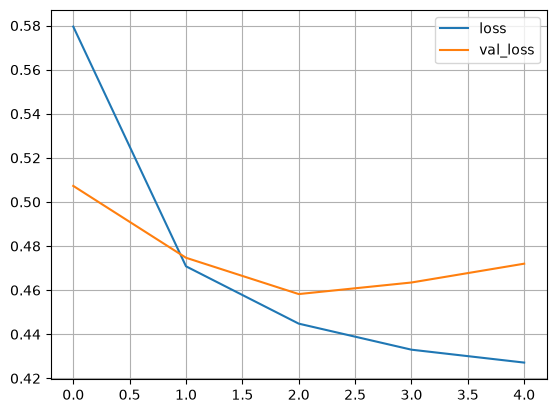

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()